# Cell Phone Price Prediction

## 1. Business Understanding

### Problem Statement

Bob has started his own mobile phone company and wants to compete with established companies in the mobile phone market. However, he does not know how to estimate the price range of the mobile phones his company produces.

To solve this problem, historical mobile phone sales data is used to identify the relationship between mobile phone specifications and their price range.

The objective is to build a Machine Learning model that can predict the price range of a mobile phone based on its specifications such as battery power, RAM, internal memory, camera specifications, screen dimensions, pixel resolution, 3G/4G support, Wi-Fi, Bluetooth, and other features.

### Business Objective

The model will help the company estimate the appropriate price range of a new mobile phone based on its specifications.

This can help the business:

- Understand the relationship between mobile specifications and price range.
- Identify the features that have the greatest influence on price range.
- Support mobile product and pricing decisions.
- Compare different mobile specifications across price categories.
- Use data-driven insights when developing new mobile phones.

### Machine Learning Objective

This is a **Supervised Machine Learning Classification** problem.

The target variable is:

`price_range`

where:

- `0` → Low Cost
- `1` → Medium Cost
- `2` → High Cost
- `3` → Very High Cost

The model will learn the relationship between the mobile phone specifications and the known price ranges and then predict the price range of new mobile phones.

## 2. Data Understanding

### Import Libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

### Load Dataset

In [3]:
df = pd.read_csv("datasets_11167_15520_train.csv")
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [4]:
df.shape #Checking Shape

(2000, 21)

In [5]:
df.info() # checking dataset information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [6]:
df.describe() # Statistical Summary

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [7]:
df.isnull().sum() # checking missing values

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

In [8]:
df.duplicated().sum() # checking duplicate values

np.int64(0)

In [9]:
df.nunique() # check unique values

battery_power    1094
blue                2
clock_speed        26
dual_sim            2
fc                 20
four_g              2
int_memory         63
m_dep              10
mobile_wt         121
n_cores             8
pc                 21
px_height        1137
px_width         1109
ram              1562
sc_h               15
sc_w               19
talk_time          19
three_g             2
touch_screen        2
wifi                2
price_range         4
dtype: int64

## In Data Understanding

- Dataset contains **2000 rows and 21 columns**.
- There are **20 input features** and **1 target variable**.
- Target variable: `price_range`
- No missing values were found.
- No duplicate records were found.
- Data types and statistical summary were checked.

## 3. Exploratory Data Analysis (EDA)

In [10]:
df['price_range'].value_counts().sort_index() # Price Range Distribution

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64

#### Visualization

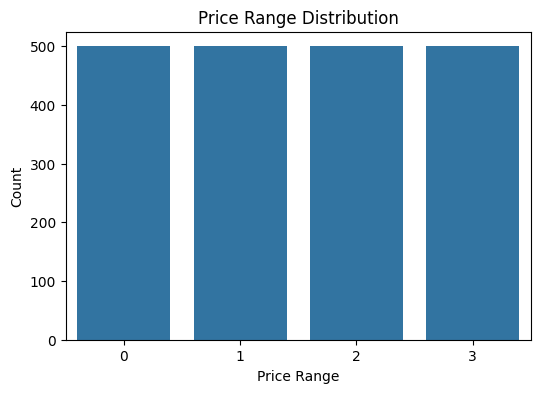

In [11]:
plt.figure(figsize=(6,4))

sns.countplot(x='price_range', data=df)

plt.title('Price Range Distribution')
plt.xlabel('Price Range')
plt.ylabel('Count')

plt.show()

#### Analyze Numerical Features

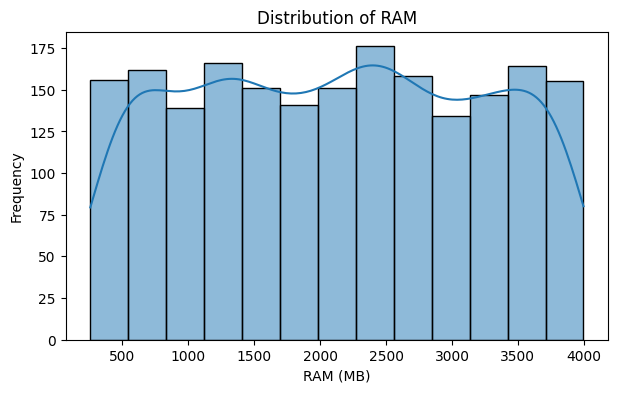

In [12]:
plt.figure(figsize=(7,4))

sns.histplot(df['ram'], kde=True)

plt.title('Distribution of RAM')
plt.xlabel('RAM (MB)')
plt.ylabel('Frequency')

plt.show()

#### Check Numerical Features Together

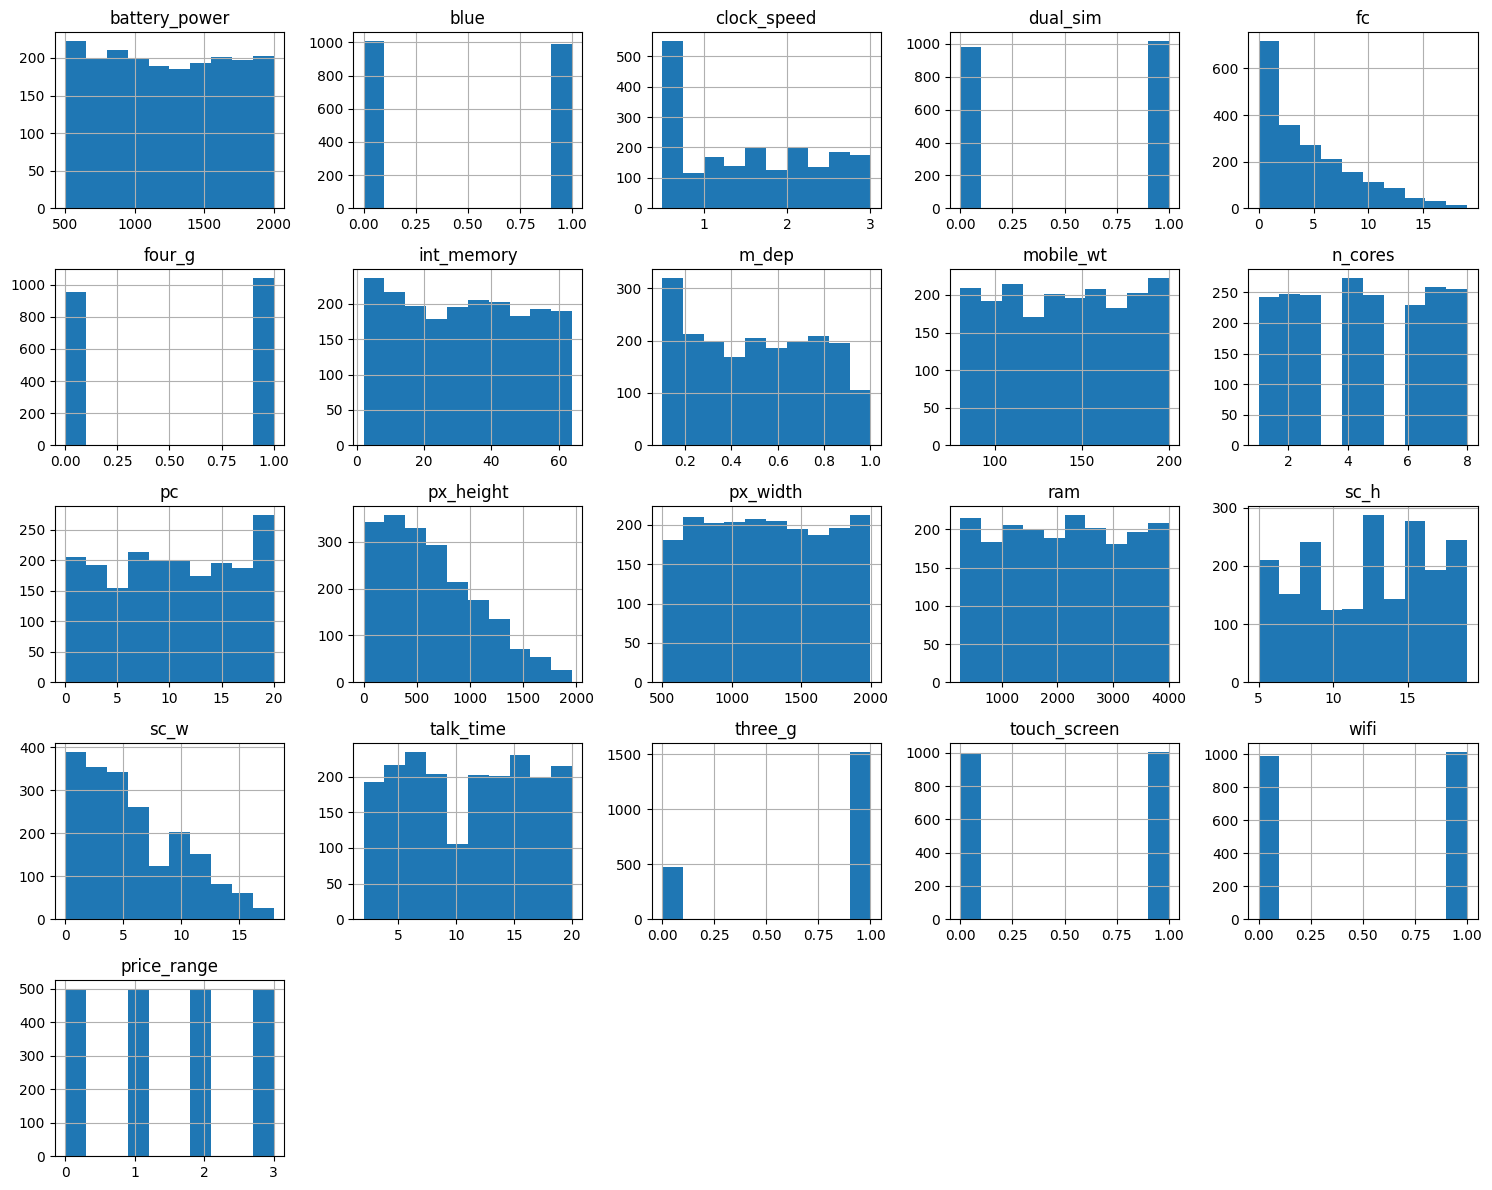

In [13]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

df[num_cols].hist(figsize=(15,12))

plt.tight_layout()
plt.show()

#### Analyze Binary Features
Many columns in our dataset contain only 0 and 1, such as Bluetooth, Wi-Fi, 3G, 4G, dual SIM, etc.

In [14]:
binary_cols = [
    'blue',
    'dual_sim',
    'four_g',
    'three_g',
    'touch_screen',
    'wifi'
]

df[binary_cols].nunique()

blue            2
dual_sim        2
four_g          2
three_g         2
touch_screen    2
wifi            2
dtype: int64

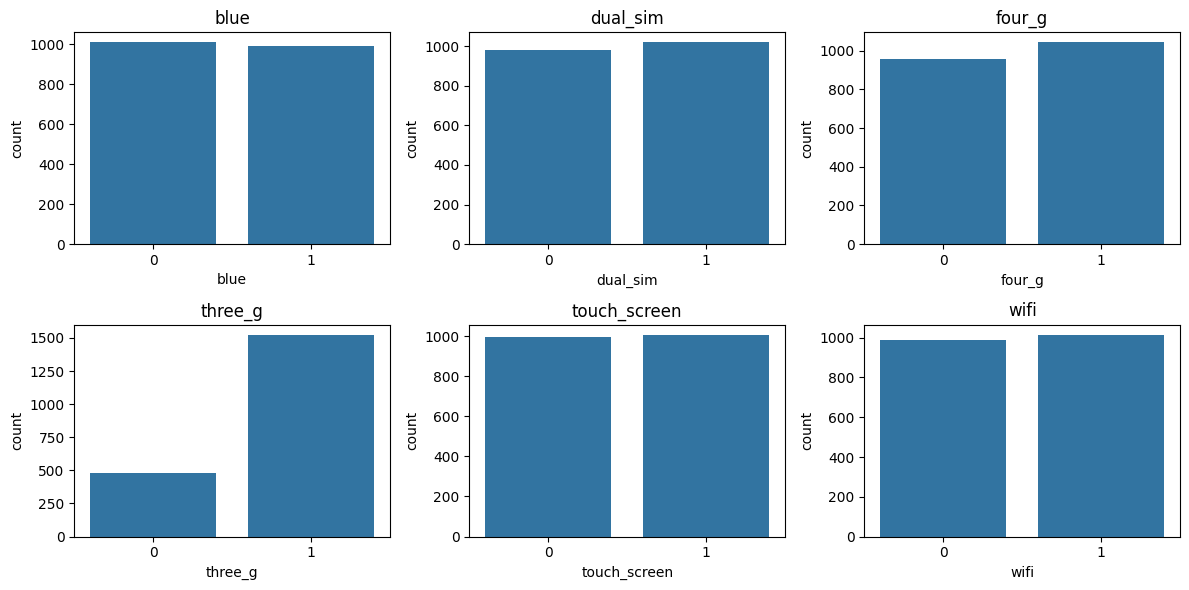

In [15]:
plt.figure(figsize=(12,6))

for i, col in enumerate(binary_cols):
    plt.subplot(2, 3, i+1)
    sns.countplot(x=col, data=df)
    plt.title(col)

plt.tight_layout()
plt.show()

#### Outlier Analysis

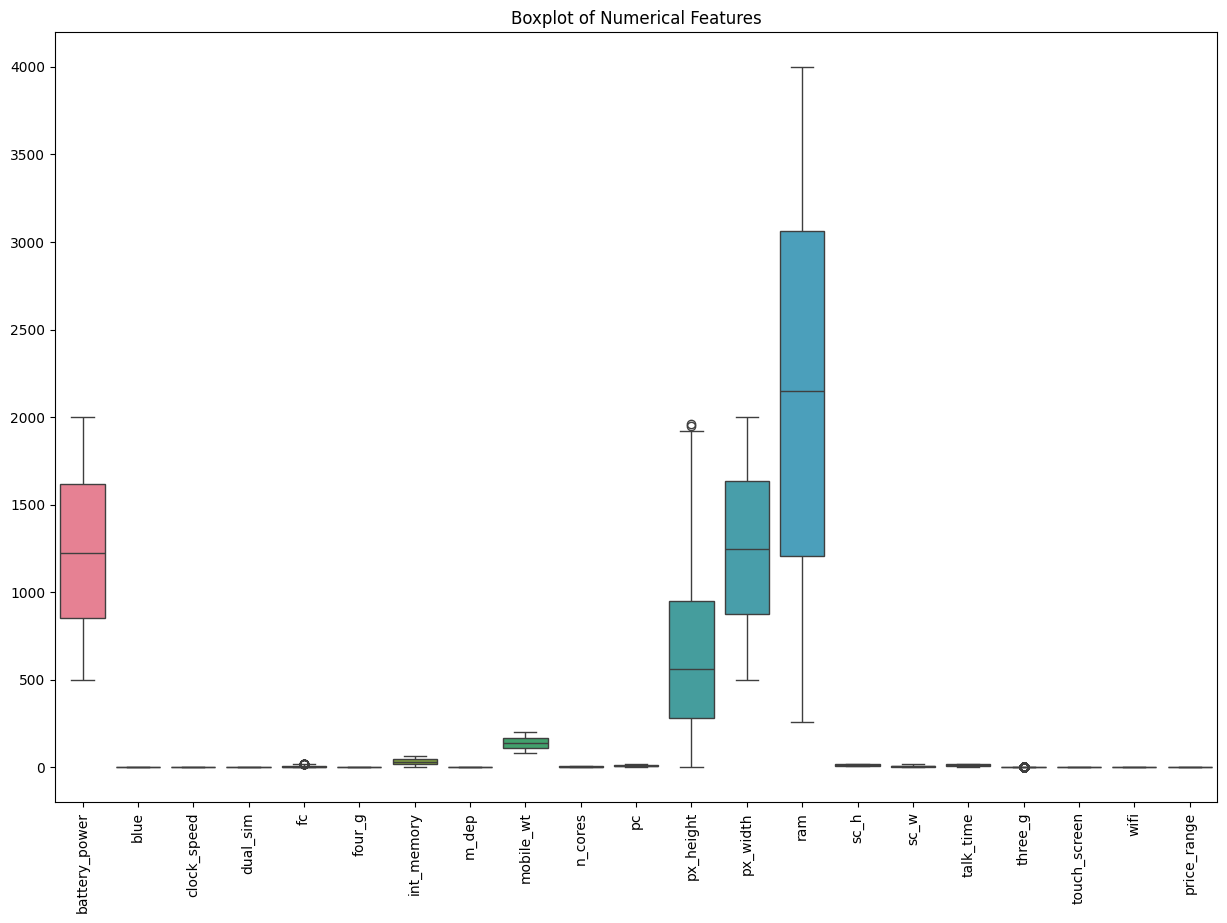

In [16]:
plt.figure(figsize=(15,10))

sns.boxplot(data=df[num_cols])

plt.xticks(rotation=90)
plt.title('Boxplot of Numerical Features')

plt.show()

#### Check Skewness

In [17]:
df[num_cols].skew()

battery_power    0.031898
blue             0.020016
clock_speed      0.178084
dual_sim        -0.038035
fc               1.019811
four_g          -0.086144
int_memory       0.057889
m_dep            0.089082
mobile_wt        0.006558
n_cores          0.003628
pc               0.017306
px_height        0.666271
px_width         0.014787
ram              0.006628
sc_h            -0.098884
sc_w             0.633787
talk_time        0.009512
three_g         -1.228142
touch_screen    -0.012009
wifi            -0.028024
price_range      0.000000
dtype: float64

#### Correlation Analysis

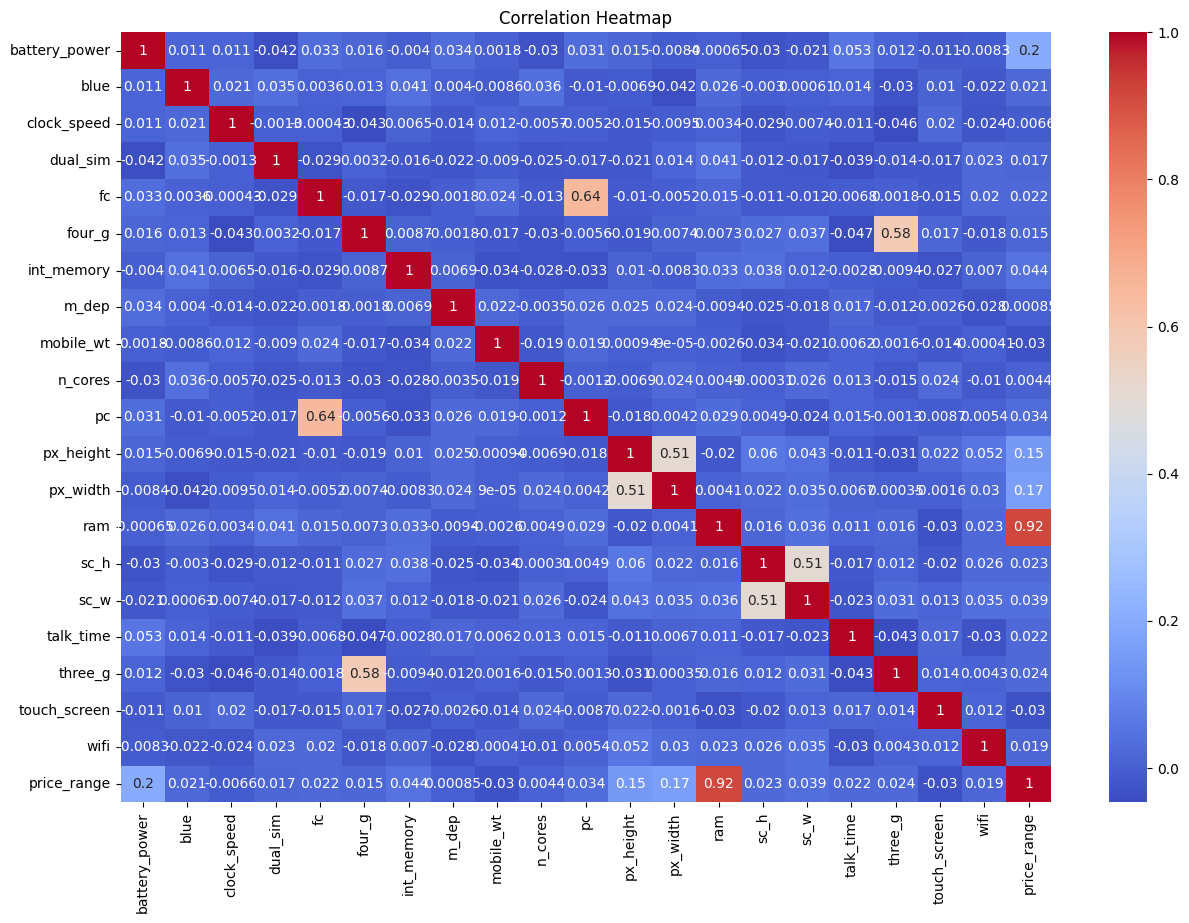

In [18]:
plt.figure(figsize=(15,10))

sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')

plt.show()

#### Feature vs Price Range

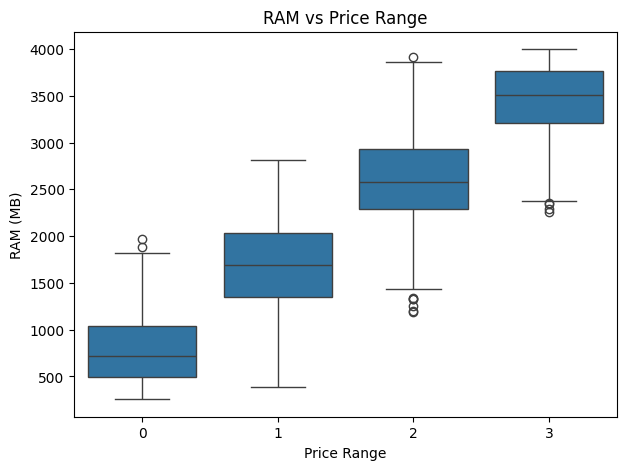

In [19]:
plt.figure(figsize=(7,5))

sns.boxplot(x='price_range', y='ram', data=df)

plt.title('RAM vs Price Range')
plt.xlabel('Price Range')
plt.ylabel('RAM (MB)')

plt.show()

#### Battery Power vs Price Range

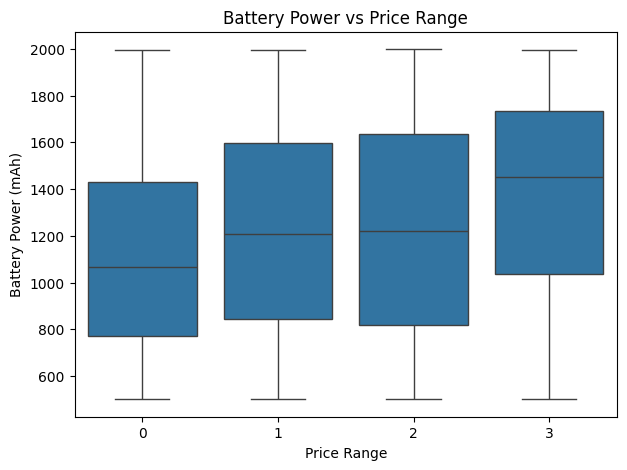

In [20]:
plt.figure(figsize=(7,5))

sns.boxplot(x='price_range', y='battery_power', data=df)

plt.title('Battery Power vs Price Range')
plt.xlabel('Price Range')
plt.ylabel('Battery Power (mAh)')

plt.show()

#### Pixel Resolution vs Price Range

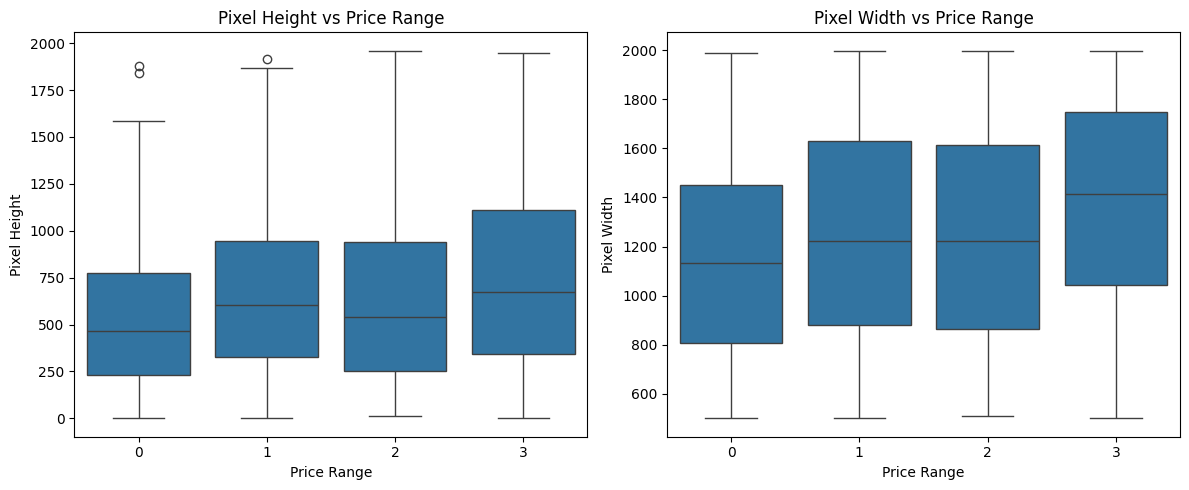

In [21]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.boxplot(x='price_range', y='px_height', data=df)
plt.title('Pixel Height vs Price Range')
plt.xlabel('Price Range')
plt.ylabel('Pixel Height')

plt.subplot(1,2,2)
sns.boxplot(x='price_range', y='px_width', data=df)
plt.title('Pixel Width vs Price Range')
plt.xlabel('Price Range')
plt.ylabel('Pixel Width')

plt.tight_layout()
plt.show()

#### Internal Memory vs Price Range

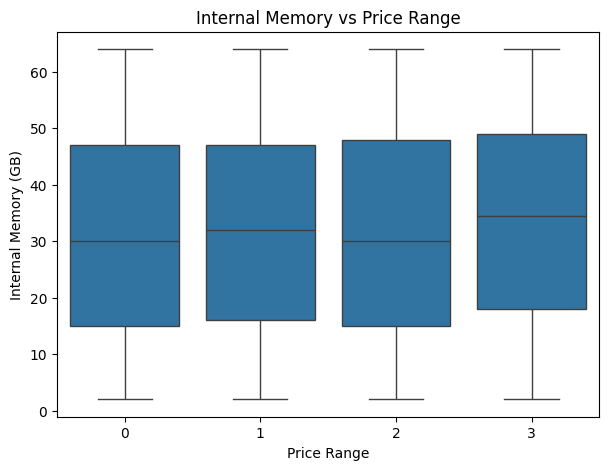

In [22]:
plt.figure(figsize=(7,5))

sns.boxplot(x='price_range', y='int_memory', data=df)

plt.title('Internal Memory vs Price Range')
plt.xlabel('Price Range')
plt.ylabel('Internal Memory (GB)')

plt.show()

#### Camera Features vs Price Range

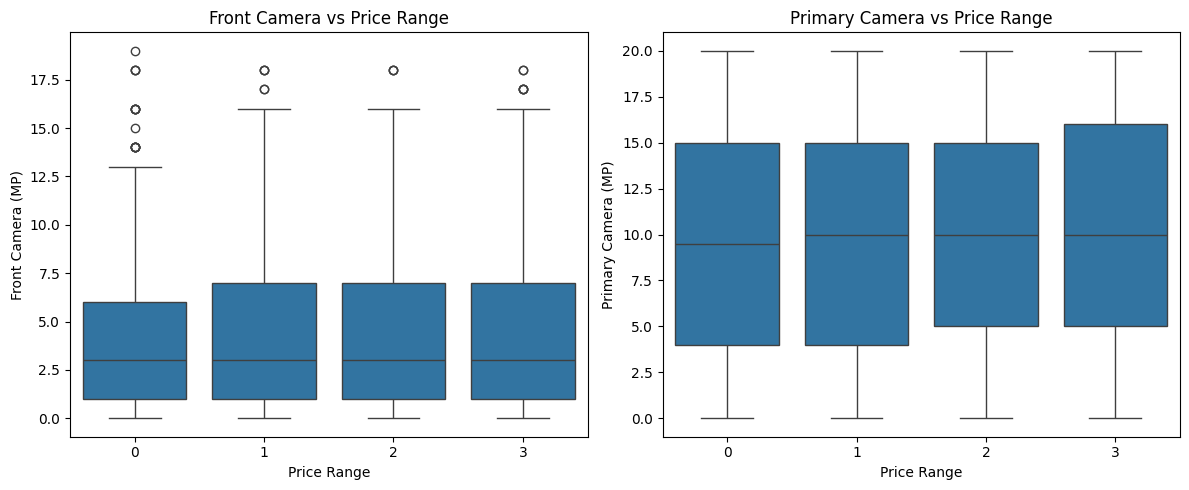

In [23]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.boxplot(x='price_range', y='fc', data=df)
plt.title('Front Camera vs Price Range')
plt.xlabel('Price Range')
plt.ylabel('Front Camera (MP)')

plt.subplot(1,2,2)
sns.boxplot(x='price_range', y='pc', data=df)
plt.title('Primary Camera vs Price Range')
plt.xlabel('Price Range')
plt.ylabel('Primary Camera (MP)')

plt.tight_layout()
plt.show()

#### Other Important Features vs Price Range

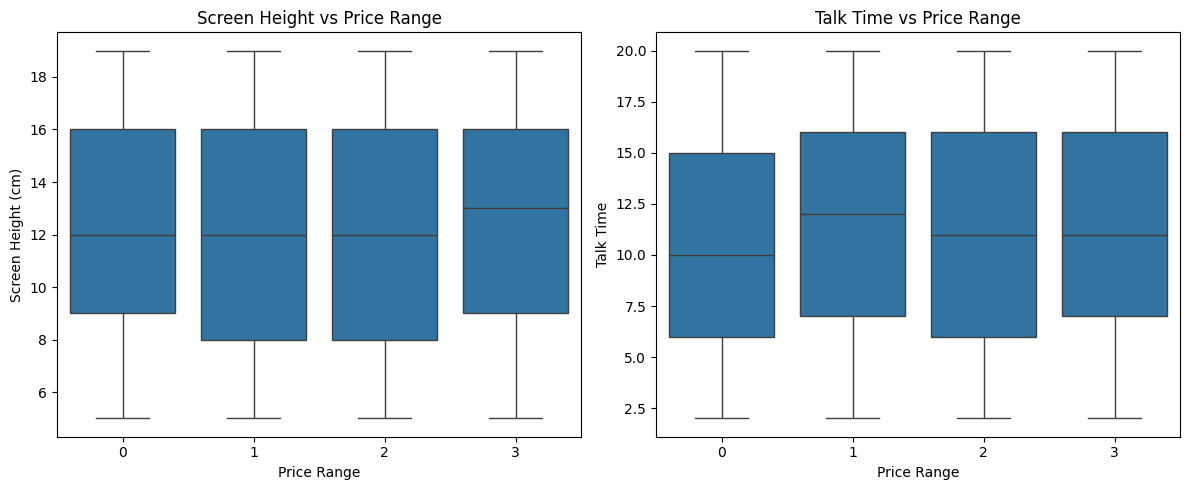

In [24]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.boxplot(x='price_range', y='sc_h', data=df)
plt.title('Screen Height vs Price Range')
plt.xlabel('Price Range')
plt.ylabel('Screen Height (cm)')

plt.subplot(1,2,2)
sns.boxplot(x='price_range', y='talk_time', data=df)
plt.title('Talk Time vs Price Range')
plt.xlabel('Price Range')
plt.ylabel('Talk Time')

plt.tight_layout()
plt.show()

### Final EDA Summary



- The target variable `price_range` contains four price categories.
- RAM shows the strongest relationship with price range.
- Battery power shows a weak positive relationship with price range.
- Pixel resolution shows a weak positive relationship with price range.
- Internal memory, screen height, and talk time show weak relationships.
- Most other features have low correlation with the target.
- Some possible outliers were observed during analysis.

# 4. Data Preprocessing

####  Separate Features and Target

In [25]:
X = df.drop('price_range', axis=1)
y = df['price_range']

In [26]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2000, 20)
y shape: (2000,)


#### Train-Test Split

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1600, 20)
X_test: (400, 20)
y_train: (1600,)
y_test: (400,)


#### Feature Scaling

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(1600, 20)
(400, 20)


# 5. Model Building

#### Logistic Regression

In [31]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [32]:
y_pred_lr = lr_model.predict(X_test_scaled)

In [33]:
print(y_pred_lr[:10])

[3 1 0 2 3 2 0 0 1 0]


#### KNN

In [34]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [35]:
y_pred_knn = knn_model.predict(X_test_scaled)

In [36]:
print(y_pred_knn[:10])

[3 2 0 1 2 2 1 1 0 1]


#### Decision Tree

In [37]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [38]:
y_pred_dt = dt_model.predict(X_test)

In [39]:
print(y_pred_dt[:10])

[3 2 0 2 3 2 0 0 1 0]


#### Random Forest

In [40]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [41]:
y_pred_rf = rf_model.predict(X_test)

In [42]:
print(y_pred_rf[:10])

[3 1 0 2 3 2 0 0 1 0]


#### SVM

In [43]:
from sklearn.svm import SVC
svm_model = SVC()
svm_model.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [44]:
y_pred_svm = svm_model.predict(X_test_scaled)

In [45]:
print(y_pred_svm[:10])

[3 1 0 1 3 2 0 0 1 0]


In [46]:
X_train_scaled
X_test_scaled

array([[ 1.22477395,  1.011314  ,  1.18747125, ...,  0.55906285,
        -1.00878862,  0.97530483],
       [ 1.70204665,  1.011314  ,  0.08647415, ...,  0.55906285,
         0.99128795,  0.97530483],
       [-1.57263781, -0.98881258, -0.64752392, ...,  0.55906285,
         0.99128795,  0.97530483],
       ...,
       [ 0.55111153,  1.011314  , -0.89218995, ..., -1.78870765,
        -1.00878862,  0.97530483],
       [ 1.55589616, -0.98881258,  0.45347318, ...,  0.55906285,
         0.99128795,  0.97530483],
       [-1.2346648 , -0.98881258, -1.25918898, ..., -1.78870765,
        -1.00878862,  0.97530483]], shape=(400, 20))

#### Gradient Boosting

In [47]:
from sklearn.ensemble import GradientBoostingClassifier
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [48]:
y_pred_gb = gb_model.predict(X_test)

In [49]:
print(y_pred_gb[:10])

[3 1 0 2 3 2 0 0 1 0]


# 6.Model Evaluation

#### Calculate Accuracy

In [50]:
from sklearn.metrics import accuracy_score

print("Logistic Regression:", accuracy_score(y_test, y_pred_lr))
print("KNN:", accuracy_score(y_test, y_pred_knn))
print("Decision Tree:", accuracy_score(y_test, y_pred_dt))
print("Random Forest:", accuracy_score(y_test, y_pred_rf))
print("SVM:", accuracy_score(y_test, y_pred_svm))
print("Gradient Boosting:", accuracy_score(y_test, y_pred_gb))

Logistic Regression: 0.965
KNN: 0.5
Decision Tree: 0.83
Random Forest: 0.88
SVM: 0.895
Gradient Boosting: 0.9125


#### Precision, Recall & F1-score

In [51]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Logistic Regression")
print("Precision:", precision_score(y_test, y_pred_lr, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_lr, average='weighted'))
print("F1-score:", f1_score(y_test, y_pred_lr, average='weighted'))

print("\nKNN")
print("Precision:", precision_score(y_test, y_pred_knn, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_knn, average='weighted'))
print("F1-score:", f1_score(y_test, y_pred_knn, average='weighted'))

print("\nDecision Tree")
print("Precision:", precision_score(y_test, y_pred_dt, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_dt, average='weighted'))
print("F1-score:", f1_score(y_test, y_pred_dt, average='weighted'))

print("\nRandom Forest")
print("Precision:", precision_score(y_test, y_pred_rf, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_rf, average='weighted'))
print("F1-score:", f1_score(y_test, y_pred_rf, average='weighted'))

print("\nSVM")
print("Precision:", precision_score(y_test, y_pred_svm, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_svm, average='weighted'))
print("F1-score:", f1_score(y_test, y_pred_svm, average='weighted'))

print("\nGradient Boosting")
print("Precision:", precision_score(y_test, y_pred_gb, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_gb, average='weighted'))
print("F1-score:", f1_score(y_test, y_pred_gb, average='weighted'))

Logistic Regression
Precision: 0.9650445632798573
Recall: 0.965
F1-score: 0.9649863177272501

KNN
Precision: 0.521130101168955
Recall: 0.5
F1-score: 0.5053550007497375

Decision Tree
Precision: 0.8318831447022742
Recall: 0.83
F1-score: 0.830168476083014

Random Forest
Precision: 0.8796143627400944
Recall: 0.88
F1-score: 0.8797343764416595

SVM
Precision: 0.8968595976126299
Recall: 0.895
F1-score: 0.8956306226521207

Gradient Boosting
Precision: 0.9124314424946206
Recall: 0.9125
F1-score: 0.9122945046229469


## Model Description

### 1. Logistic Regression
Logistic Regression is a classification algorithm that estimates the probability of each class and assigns the input to the most suitable class.

In this project, it is used to classify mobile phones into four price ranges.

### 2. K-Nearest Neighbors (KNN)
KNN classifies a new mobile phone based on the price ranges of its nearest neighboring phones.

Since KNN is distance-based, feature scaling was applied before training.

### 3. Decision Tree
Decision Tree is a tree-based classification algorithm that makes predictions using a sequence of feature-based decisions.

It does not require feature scaling.

### 4. Random Forest
Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to make a more reliable prediction.

It can capture complex relationships between mobile specifications and price range.

### 5. Support Vector Machine (SVM)
SVM finds a suitable decision boundary to separate different price-range classes.

Since SVM is sensitive to feature scale, scaled data was used.

### 6. Gradient Boosting
Gradient Boosting is an ensemble technique that builds models sequentially, where each new model focuses on improving the errors of previous models.

It can capture complex patterns in the data.

## Initial Model Evaluation

The models were evaluated using Precision, Recall, and F1-score. Logistic Regression achieved the highest scores on the initial test set, followed by Gradient Boosting, SVM, Random Forest, Decision Tree, and KNN.

However, the final model selection will be performed after cross-validation and hyperparameter tuning.

# 7.Confusion Matrix

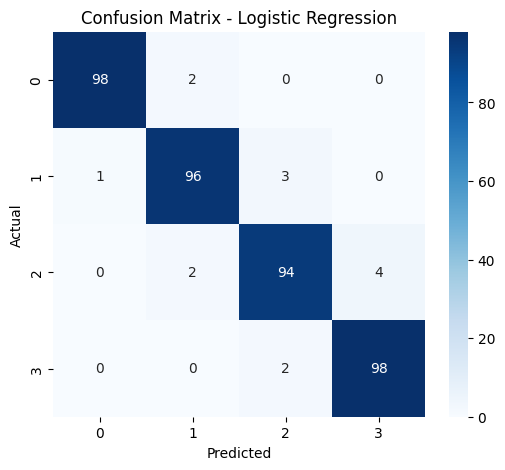

In [52]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,5))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# 8. Classification Report

### Classification Report of Logistic Regression

In [53]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=[
        'Low Cost',
        'Medium Cost',
        'High Cost',
        'Very High Cost'
    ]
))

                precision    recall  f1-score   support

      Low Cost       0.99      0.98      0.98       100
   Medium Cost       0.96      0.96      0.96       100
     High Cost       0.95      0.94      0.94       100
Very High Cost       0.96      0.98      0.97       100

      accuracy                           0.96       400
     macro avg       0.97      0.96      0.96       400
  weighted avg       0.97      0.96      0.96       400



### Classification Report of KNN

In [54]:
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=[
        'Low Cost',
        'Medium Cost',
        'High Cost',
        'Very High Cost'
    ]
))

                precision    recall  f1-score   support

      Low Cost       0.65      0.70      0.67       100
   Medium Cost       0.33      0.38      0.35       100
     High Cost       0.39      0.41      0.40       100
Very High Cost       0.72      0.51      0.60       100

      accuracy                           0.50       400
     macro avg       0.52      0.50      0.51       400
  weighted avg       0.52      0.50      0.51       400



### Classification Report of Decision Tree

In [55]:
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=[
        'Low Cost',
        'Medium Cost',
        'High Cost',
        'Very High Cost'
    ]
))

                precision    recall  f1-score   support

      Low Cost       0.88      0.92      0.90       100
   Medium Cost       0.78      0.74      0.76       100
     High Cost       0.75      0.80      0.77       100
Very High Cost       0.92      0.86      0.89       100

      accuracy                           0.83       400
     macro avg       0.83      0.83      0.83       400
  weighted avg       0.83      0.83      0.83       400



### Classification Report of Random Forest

In [56]:
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=[
        'Low Cost',
        'Medium Cost',
        'High Cost',
        'Very High Cost'
    ]
))

                precision    recall  f1-score   support

      Low Cost       0.95      0.96      0.96       100
   Medium Cost       0.82      0.84      0.83       100
     High Cost       0.81      0.79      0.80       100
Very High Cost       0.93      0.93      0.93       100

      accuracy                           0.88       400
     macro avg       0.88      0.88      0.88       400
  weighted avg       0.88      0.88      0.88       400



### Classification Report of SVM

In [57]:
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=[
        'Low Cost',
        'Medium Cost',
        'High Cost',
        'Very High Cost'
    ]
))

                precision    recall  f1-score   support

      Low Cost       0.96      0.94      0.95       100
   Medium Cost       0.87      0.87      0.87       100
     High Cost       0.82      0.87      0.84       100
Very High Cost       0.94      0.90      0.92       100

      accuracy                           0.90       400
     macro avg       0.90      0.90      0.90       400
  weighted avg       0.90      0.90      0.90       400



### Classification Report of Gradient Boosting

In [58]:
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=[
        'Low Cost',
        'Medium Cost',
        'High Cost',
        'Very High Cost'
    ]
))

                precision    recall  f1-score   support

      Low Cost       0.95      0.98      0.97       100
   Medium Cost       0.90      0.86      0.88       100
     High Cost       0.85      0.87      0.86       100
Very High Cost       0.95      0.94      0.94       100

      accuracy                           0.91       400
     macro avg       0.91      0.91      0.91       400
  weighted avg       0.91      0.91      0.91       400



## Classification Report Summary

The classification reports were used to evaluate the performance of all six models.

- Logistic Regression performed the best on the initial test set with about 96% accuracy.
- Gradient Boosting achieved about 91% accuracy and showed strong performance across all four price categories.
- SVM achieved about 90% accuracy.
- Random Forest achieved about 88% accuracy.
- Decision Tree achieved about 83% accuracy.
- KNN achieved about 50% accuracy and performed poorly compared with the other models.

These results are based on the current train-test split. Cross-validation and hyperparameter tuning will be performed before selecting the final model.

# 8. Cross-Validation

In [59]:
from sklearn.model_selection import cross_val_score

# Cross-validation for Logistic Regression
cv_lr = cross_val_score(lr_model, X_train_scaled, y_train, cv=5, scoring='accuracy')

# Cross-validation for KNN
cv_knn = cross_val_score(knn_model, X_train_scaled, y_train, cv=5, scoring='accuracy')

# Cross-validation for Decision Tree
cv_dt = cross_val_score(dt_model, X_train, y_train, cv=5, scoring='accuracy')

# Cross-validation for Random Forest
cv_rf = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='accuracy')

# Cross-validation for SVM
cv_svm = cross_val_score(svm_model, X_train_scaled, y_train, cv=5, scoring='accuracy')

# Cross-validation for Gradient Boosting
cv_gb = cross_val_score(gb_model, X_train, y_train, cv=5, scoring='accuracy')


# Print mean cross-validation accuracy
print("Logistic Regression:", cv_lr.mean())
print("KNN:", cv_knn.mean())
print("Decision Tree:", cv_dt.mean())
print("Random Forest:", cv_rf.mean())
print("SVM:", cv_svm.mean())
print("Gradient Boosting:", cv_gb.mean())

Logistic Regression: 0.94625
KNN: 0.49812500000000004
Decision Tree: 0.82875
Random Forest: 0.86875
SVM: 0.859375
Gradient Boosting: 0.8868750000000001


## Cross-Validation Summary

5-fold cross-validation was performed to check the consistency of the models.

- Logistic Regression achieved the highest cross-validation accuracy of about 94.63%.
- Gradient Boosting achieved about 88.69%.
- Random Forest achieved about 86.88%.
- SVM achieved about 85.94%.
- Decision Tree achieved about 82.88%.
- KNN achieved about 49.81%.

Cross-validation confirms that Logistic Regression performs consistently well on the dataset.

# 9. Hyperparameter Tuning

In [66]:
# Hyperparameter tuning for all important models

from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# -------------------------------
# 1. Logistic Regression
# -------------------------------

lr_params = {
    'C': [0.1, 1, 10],
    'solver': ['lbfgs']
}

lr_random = RandomizedSearchCV(
    LogisticRegression(max_iter=1000),
    lr_params,
    n_iter=3,
    cv=3,
    scoring='accuracy',
    random_state=42
)

lr_random.fit(X_train_scaled, y_train)


# -------------------------------
# 2. Random Forest
# -------------------------------

rf_params = {
    'n_estimators': [100, 150],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

rf_random = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    n_iter=3,
    cv=3,
    scoring='accuracy',
    random_state=42
)

rf_random.fit(X_train, y_train)


# -------------------------------
# 3. SVM
# -------------------------------

svm_params = {
    'C': [1, 10],
    'kernel': ['rbf']
}

svm_random = RandomizedSearchCV(
    SVC(),
    svm_params,
    n_iter=2,
    cv=3,
    scoring='accuracy',
    random_state=42
)

svm_random.fit(X_train_scaled, y_train)


# -------------------------------
# 4. Gradient Boosting
# -------------------------------

gb_params = {
    'n_estimators': [100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5]
}

gb_random = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_params,
    n_iter=3,
    cv=3,
    scoring='accuracy',
    random_state=42
)

gb_random.fit(X_train, y_train)


# -------------------------------
# Print best results
# -------------------------------

print("Logistic Regression:")
print("Best Parameters:", lr_random.best_params_)
print("Best CV Accuracy:", lr_random.best_score_)

print("\nRandom Forest:")
print("Best Parameters:", rf_random.best_params_)
print("Best CV Accuracy:", rf_random.best_score_)

print("\nSVM:")
print("Best Parameters:", svm_random.best_params_)
print("Best CV Accuracy:", svm_random.best_score_)

print("\nGradient Boosting:")
print("Best Parameters:", gb_random.best_params_)
print("Best CV Accuracy:", gb_random.best_score_)

Logistic Regression:
Best Parameters: {'solver': 'lbfgs', 'C': 10}
Best CV Accuracy: 0.9593730163749347

Random Forest:
Best Parameters: {'n_estimators': 150, 'min_samples_split': 2, 'max_depth': None}
Best CV Accuracy: 0.8612452070933848

SVM:
Best Parameters: {'kernel': 'rbf', 'C': 10}
Best CV Accuracy: 0.8593772324931547

Gradient Boosting:
Best Parameters: {'n_estimators': 150, 'max_depth': 3, 'learning_rate': 0.1}
Best CV Accuracy: 0.8856331087079238


## Hyperparameter Tuning Summary

RandomizedSearchCV was used to tune the important models.

- Logistic Regression achieved a CV accuracy of **95.94%**.
- Random Forest achieved a CV accuracy of **86.12%**.
- SVM achieved a CV accuracy of **85.94%**.
- Gradient Boosting achieved a CV accuracy of **88.56%**.

The tuned Logistic Regression model showed an improvement over its previous cross-validation accuracy.

Hyperparameter tuning does not always improve every model because the performance depends on the selected parameters and dataset.

# 10. Feature Importance

          Feature  Importance
13            ram    0.483022
0   battery_power    0.073482
12       px_width    0.056920
11      px_height    0.055433
8       mobile_wt    0.038979
6      int_memory    0.035094
16      talk_time    0.030602
10             pc    0.029848
15           sc_w    0.027891
14           sc_h    0.027857
2     clock_speed    0.027691
7           m_dep    0.025324
4              fc    0.025212
9         n_cores    0.023673
1            blue    0.007121
18   touch_screen    0.007037
3        dual_sim    0.006952
5          four_g    0.006726
19           wifi    0.006384
17        three_g    0.004752


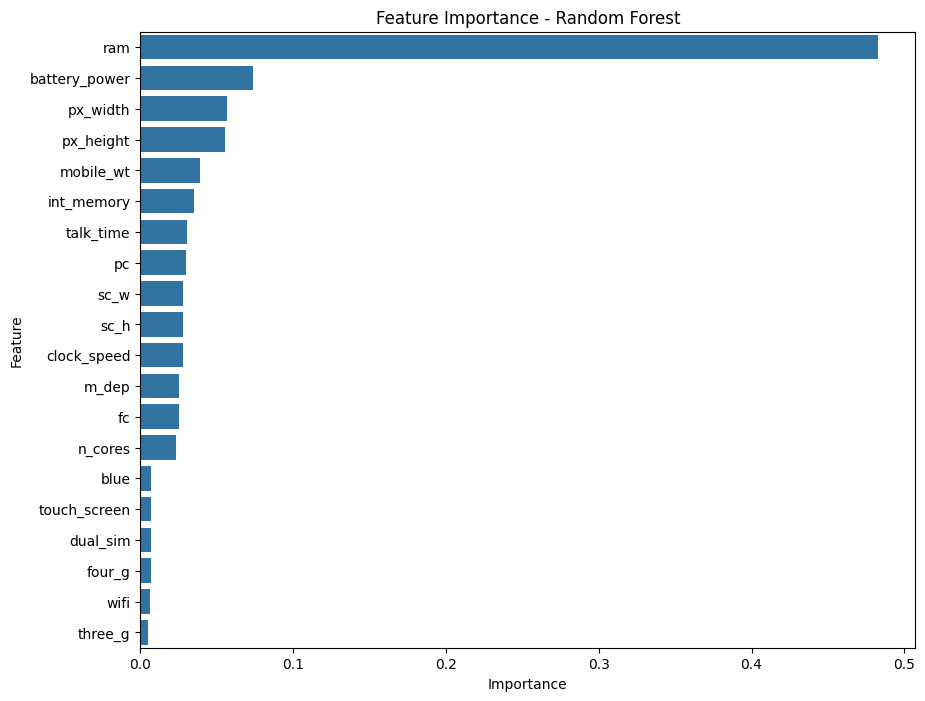

In [67]:
# Feature Importance using Random Forest

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance from the Random Forest model
feature_importance = rf_random.best_estimator_.feature_importances_

# Create a DataFrame with feature names and importance values
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
})

# Sort features from highest to lowest importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display feature importance values
print(importance_df)

# Plot the feature importance
plt.figure(figsize=(10, 8))
sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

# 11. Final Model Evaluation

Final Model Accuracy: 0.975

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       100
           1       0.98      0.96      0.97       100
           2       0.95      0.98      0.97       100
           3       0.98      0.98      0.98       100

    accuracy                           0.97       400
   macro avg       0.98      0.97      0.98       400
weighted avg       0.98      0.97      0.98       400



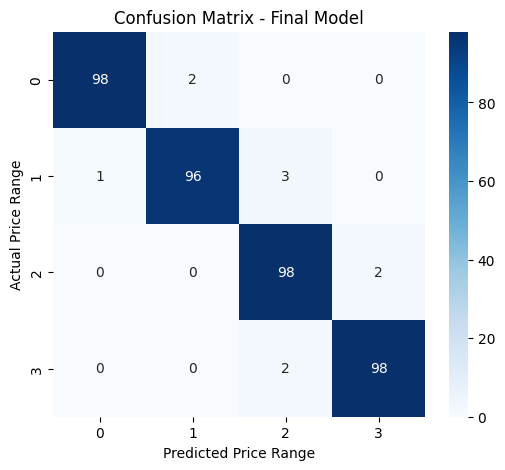

In [68]:
# Final Model Evaluation

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Select the tuned Logistic Regression model
final_model = lr_random.best_estimator_

# Make predictions
y_pred_final = final_model.predict(X_test_scaled)

# Calculate accuracy
final_accuracy = accuracy_score(y_test, y_pred_final)

print("Final Model Accuracy:", final_accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix - Final Model')
plt.xlabel('Predicted Price Range')
plt.ylabel('Actual Price Range')
plt.show()

# 12. Business Analysis



The Machine Learning model can help the mobile company make data-driven decisions about mobile phone pricing.

### Business Insights

- RAM is the most important feature in the Random Forest feature-importance analysis.
- Battery power is another important feature for predicting price range.
- Pixel resolution features such as `px_width` and `px_height` also contribute to price prediction.
- The company can use these insights while designing mobile phones for different price segments.
- The model can help classify new mobile phones into low, medium, high, and very high price ranges.
- Feature importance can help the company understand which specifications are more relevant when developing new products.

### Business Benefits

The model can help the company:

1. Design mobile phones according to different price segments.
2. Understand the relationship between specifications and price range.
3. Support data-driven pricing decisions.
4. Identify important specifications for new products.
5. Compete more effectively by understanding the specifications associated with different price ranges.

## 13. Challenges Faced and Techniques Used

### Challenges Faced

- Different machine learning models showed different levels of performance.
- KNN performed poorly compared with the other models.
- Hyperparameter tuning required more computational time for some models.
- Some features had weak relationships with the target variable.
- Possible outliers were observed during EDA.

### Techniques Used

- Exploratory Data Analysis (EDA)
- Train-test split
- Stratified sampling
- Feature scaling using StandardScaler
- Multiple classification algorithms
- Cross-validation
- RandomizedSearchCV for hyperparameter tuning
- Confusion matrix and classification report
- Feature importance analysis

### Reason for Using These Techniques

These techniques were used to understand the dataset, prepare the data, compare different classification models, improve model performance, and identify the features that are most useful for predicting mobile phone price ranges.